In [921]:
import sklearn
from sklearn.datasets import make_circles

In [922]:
n_samples=1000

X, y = make_circles(n_samples,noise=0.03,random_state=42)

In [923]:
len(X),len(y)

(1000, 1000)

In [924]:
print(X[:5])

[[ 0.75424625  0.23148074]
 [-0.75615888  0.15325888]
 [-0.81539193  0.17328203]
 [-0.39373073  0.69288277]
 [ 0.44220765 -0.89672343]]


In [925]:
print(y[:5])

[1 1 1 1 0]


In [926]:
import pandas as pd
circles=pd.DataFrame({"X1":X[:,0],"X2":X[:,1],"label":y})

In [927]:
circles.head(10)

,X1,X2,label
0,0.754246,0.231481,1
1,-0.756159,0.153259,1
2,-0.815392,0.173282,1
3,-0.393731,0.692883,1
4,0.442208,-0.896723,0
5,-0.479646,0.676435,1
6,-0.013648,0.803349,1
7,0.771513,0.147760,1
8,-0.169322,-0.793456,1
9,-0.121486,1.021509,0


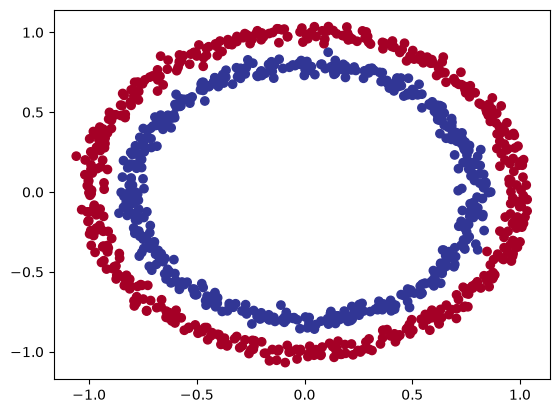

In [928]:
import matplotlib.pyplot as plt
plt.scatter(x=X[:,0],y=X[:,1],c=y,cmap=plt.cm.RdYlBu)

In [929]:
X.shape

(1000, 2)

In [930]:
y.shape

(1000,)

In [931]:
import torch

X_sample=X[0]
y_sample=y[0]

print(X_sample,y_sample)
print(X_sample.shape,y_sample.shape)

[0.75424625 0.23148074] 1
(2,) ()


In [932]:
device="cuda" if torch.cuda.is_available() else "cpu"

In [933]:
type(X)

numpy.ndarray

In [934]:
X=torch.from_numpy(X).type(torch.float)
y=torch.from_numpy(y).type(torch.float)

In [935]:
type(X)
type(y)

torch.Tensor

In [936]:
X[:5],y[:5]

(tensor([[ 0.7542,  0.2315],
         [-0.7562,  0.1533],
         [-0.8154,  0.1733],
         [-0.3937,  0.6929],
         [ 0.4422, -0.8967]]),
 tensor([1., 1., 1., 1., 0.]))

In [937]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [938]:
len(X_train),len(X_test),len(y_train),len(y_test)

(800, 200, 800, 200)

In [939]:
n_samples

1000

In [940]:
from torch import nn
device="cuda" if torch.cuda.is_available() else "cpu"

In [941]:
device

'cuda'

In [942]:
X_train

tensor([[ 0.6579, -0.4651],
        [ 0.6319, -0.7347],
        [-1.0086, -0.1240],
        ...,
        [ 0.0157, -1.0300],
        [ 1.0110,  0.1680],
        [ 0.5578, -0.5709]])

In [943]:
class CircleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer1=nn.Linear(in_features=2,out_features=5)
        self.linear_layer2=nn.Linear(in_features=5,out_features=1)

    def forward(self,X):
        return self.linear_layer2(self.linear_layer1(X))

model=CircleModel().to(device)
model

CircleModel(
  (linear_layer1): Linear(in_features=2, out_features=5, bias=True)
  (linear_layer2): Linear(in_features=5, out_features=1, bias=True)
)

In [944]:
device

'cuda'

In [945]:
next(model.parameters()).device

device(type='cuda', index=0)

In [946]:
model=nn.Sequential(
    nn.Linear(in_features=2,out_features=5),
    nn.Linear(in_features=5,out_features=1)

).to(device)
model

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [947]:
model.state_dict()

OrderedDict([('0.weight',
              tensor([[ 0.0910, -0.6231],
                      [ 0.2968, -0.1061],
                      [-0.3239,  0.6074],
                      [ 0.1576, -0.3912],
                      [-0.3579, -0.0338]], device='cuda:0')),
             ('0.bias',
              tensor([ 0.3948, -0.1807, -0.4035, -0.2421, -0.5283], device='cuda:0')),
             ('1.weight',
              tensor([[ 0.1595,  0.3462, -0.4210,  0.1039,  0.2310]], device='cuda:0')),
             ('1.bias', tensor([0.0811], device='cuda:0'))])

In [948]:
with torch.inference_mode(): 
    untrained_pred=model(X_test.to(device))
print(len(untrained_pred))
print(untrained_pred.shape)
print(len(X_test))
print(X_test.shape)
print(untrained_pred[:10])
print(y_test[:10])

200
torch.Size([200, 1])
200
torch.Size([200, 2])
tensor([[-0.2666],
        [-0.3156],
        [ 0.1111],
        [-0.3747],
        [ 0.5070],
        [ 0.4741],
        [ 0.0224],
        [ 0.2084],
        [ 0.0938],
        [-0.3145]], device='cuda:0')
tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [949]:
X_test[:10],y_test[:10]

(tensor([[-0.3752,  0.6827],
         [ 0.0154,  0.9600],
         [-0.7028, -0.3147],
         [-0.2853,  0.9664],
         [ 0.4024, -0.7438],
         [ 0.6323, -0.5711],
         [ 0.8561,  0.5499],
         [ 1.0034,  0.1903],
         [-0.7489, -0.2951],
         [ 0.0538,  0.9739]]),
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.]))

In [950]:
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.SGD(params=model.parameters(),lr=0.1)

In [951]:
model.state_dict()

OrderedDict([('0.weight',
              tensor([[ 0.0910, -0.6231],
                      [ 0.2968, -0.1061],
                      [-0.3239,  0.6074],
                      [ 0.1576, -0.3912],
                      [-0.3579, -0.0338]], device='cuda:0')),
             ('0.bias',
              tensor([ 0.3948, -0.1807, -0.4035, -0.2421, -0.5283], device='cuda:0')),
             ('1.weight',
              tensor([[ 0.1595,  0.3462, -0.4210,  0.1039,  0.2310]], device='cuda:0')),
             ('1.bias', tensor([0.0811], device='cuda:0'))])

In [952]:
def accuracy_fn(y_true,y_pred):
    correct=torch.eq(y_true,y_pred).sum().item()
    acc=(correct/len(y_pred))*100
    return acc

In [953]:
with torch.inference_mode():
    y_logits=model(X_test.to(device))[:5]
y_logits

tensor([[-0.2666],
        [-0.3156],
        [ 0.1111],
        [-0.3747],
        [ 0.5070]], device='cuda:0')

In [954]:
y_test[:5]

tensor([1., 0., 1., 0., 1.])

In [955]:
y_pred_probs=torch.sigmoid(y_logits)
y_pred_probs

tensor([[0.4337],
        [0.4218],
        [0.5277],
        [0.4074],
        [0.6241]], device='cuda:0')

In [956]:
torch.round(y_pred_probs)

tensor([[0.],
        [0.],
        [1.],
        [0.],
        [1.]], device='cuda:0')

In [957]:
y_preds=torch.round(y_pred_probs)

y_pred_labels=torch.round(torch.sigmoid(model(X_test.to(device))[:5]))

print(torch.eq(y_preds.squeeze(),y_pred_labels.squeeze()))
y_preds.squeeze()

tensor([True, True, True, True, True], device='cuda:0')


tensor([0., 0., 1., 0., 1.], device='cuda:0')

In [958]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)
epocs=200

X_train=X_train.to(device)
y_train=y_train.to(device)
X_test=X_test.to(device)
y_test=y_test.to(device)

for epoc in range(epocs):
    
    model.train()

    y_logits=model(X_train).squeeze()

    y_pred=torch.round(torch.sigmoid(y_logits))

    loss=loss_fn(y_logits,y_train)

    acc=accuracy_fn(y_true=y_train,y_pred=y_pred)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model.eval()

    with torch.inference_mode():
        test_logits=model(X_test).squeeze()
        test_pred=torch.round(torch.sigmoid(test_logits))

        test_loss=loss_fn(test_logits,y_test)
        test_acc=accuracy_fn(y_true=y_test,y_pred=test_pred)

    if epoc%10==0:
        print(f"Epoc: {epoc} | Loss: {loss:.5f}, Acc: {acc:.2f} | Test loss: {test_loss:.5f} | Text acc: {test_acc:.2f}%")

Epoc: 0 | Loss: 0.70840, Acc: 50.62 | Test loss: 0.69714 | Text acc: 50.50%
Epoc: 10 | Loss: 0.70332, Acc: 50.25 | Test loss: 0.69458 | Text acc: 51.50%
Epoc: 20 | Loss: 0.70051, Acc: 49.62 | Test loss: 0.69341 | Text acc: 51.50%
Epoc: 30 | Loss: 0.69873, Acc: 49.62 | Test loss: 0.69281 | Text acc: 50.50%
Epoc: 40 | Loss: 0.69748, Acc: 49.12 | Test loss: 0.69246 | Text acc: 50.50%
Epoc: 50 | Loss: 0.69656, Acc: 49.25 | Test loss: 0.69227 | Text acc: 50.00%
Epoc: 60 | Loss: 0.69585, Acc: 49.25 | Test loss: 0.69217 | Text acc: 50.00%
Epoc: 70 | Loss: 0.69530, Acc: 48.75 | Test loss: 0.69214 | Text acc: 50.50%
Epoc: 80 | Loss: 0.69486, Acc: 48.62 | Test loss: 0.69215 | Text acc: 51.00%
Epoc: 90 | Loss: 0.69451, Acc: 48.62 | Test loss: 0.69220 | Text acc: 51.50%
Epoc: 100 | Loss: 0.69423, Acc: 48.62 | Test loss: 0.69227 | Text acc: 52.00%
Epoc: 110 | Loss: 0.69401, Acc: 48.88 | Test loss: 0.69236 | Text acc: 51.50%
Epoc: 120 | Loss: 0.69382, Acc: 48.75 | Test loss: 0.69246 | Text acc: 51.5

In [959]:
import requests
from pathlib import Path
if Path("helper_functions.py").is_file():
    print("helper_functions already exsists")
else:
    print("Download helper_functions.py")
    request=requests.get("https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/helper_functions.py")
    with open("helper_functions.py", "wb") as f:
        f.write(request.content)
from helper_functions import plot_predictions,plot_decision_boundary

helper_functions already exsists


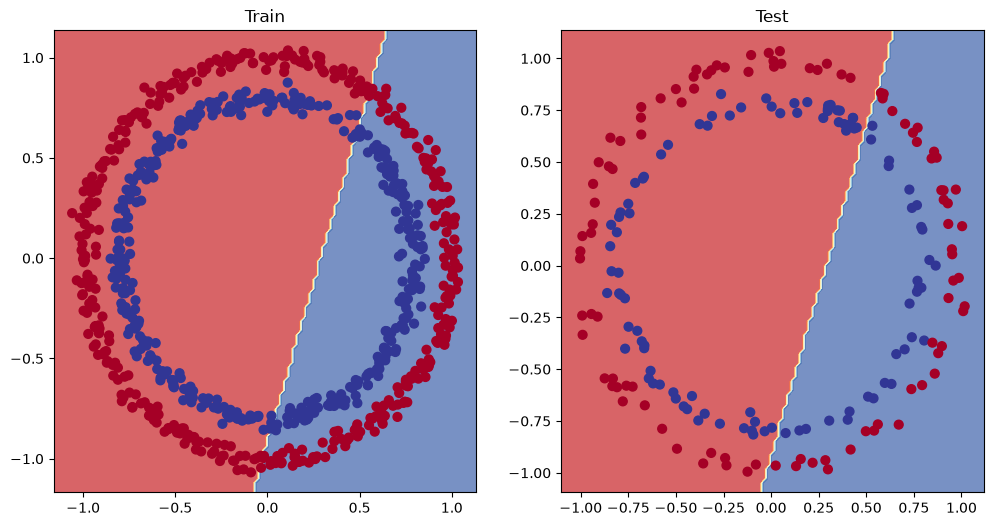

In [960]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model,X_train,y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model,X_test,y_test)


In [961]:
model.state_dict()

OrderedDict([('0.weight',
              tensor([[ 0.0858, -0.6100],
                      [ 0.2663,  0.0167],
                      [-0.2945,  0.4951],
                      [ 0.1538, -0.3818],
                      [-0.3819,  0.0644]])),
             ('0.bias', tensor([ 0.3902, -0.1726, -0.4064, -0.2455, -0.5201])),
             ('1.weight',
              tensor([[-0.0710,  0.2978, -0.1950, -0.0641,  0.2559]])),
             ('1.bias', tensor([0.1105]))])

In [962]:
class CircleModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.layer_1=nn.Linear(in_features=2,out_features=10)
        self.layer_2=nn.Linear(in_features=10,out_features=10)
        self.layer_3=nn.Linear(in_features=10,out_features=1)
    def forward(self,X):
        return self.layer_3(self.layer_2(self.layer_1(X)))

model_1=CircleModel().to(device)
model_1

CircleModel(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [963]:
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.SGD(params=model_1.parameters(),lr=0.1)

In [964]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

epocs=1000

X_train=X_train.to(device)
X_test=X_test.to(device)
y_train=y_train.to(device)
y_test=y_test.to(device)

for epoc in range(epocs):
    model_1.train()

    y_logits=model_1(X_train).squeeze()

    y_pred=torch.round(torch.sigmoid(y_logits))

    loss=loss_fn(y_logits,y_train)

    acc=accuracy_fn(y_true=y_train,y_pred=y_pred)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model_1.eval()

    with torch.inference_mode():
        test_logits=model_1(X_test).squeeze()
        test_pred=torch.round(torch.sigmoid(test_logits))

        test_loss=loss_fn(test_logits,y_test)

        test_acc=accuracy_fn(y_true=y_test,y_pred=test_pred)


    if epoc%100==0:
        print(f"Epoc: {epoc} | Loss: {loss},Acc: {acc} | Test loss: {test_loss} | Test Acc: {test_acc}")

Epoc: 0 | Loss: 0.6939550638198853,Acc: 50.875 | Test loss: 0.6926146745681763 | Test Acc: 51.0
Epoc: 100 | Loss: 0.6930478811264038,Acc: 50.375 | Test loss: 0.6937904357910156 | Test Acc: 48.0
Epoc: 200 | Loss: 0.6929860711097717,Acc: 51.125 | Test loss: 0.6943727135658264 | Test Acc: 46.0
Epoc: 300 | Loss: 0.6929804682731628,Acc: 51.625 | Test loss: 0.6945767998695374 | Test Acc: 45.0
Epoc: 400 | Loss: 0.6929798722267151,Acc: 51.125 | Test loss: 0.6946452260017395 | Test Acc: 46.0
Epoc: 500 | Loss: 0.6929798722267151,Acc: 51.0 | Test loss: 0.6946679353713989 | Test Acc: 46.0
Epoc: 600 | Loss: 0.6929798722267151,Acc: 51.0 | Test loss: 0.6946756839752197 | Test Acc: 46.0
Epoc: 700 | Loss: 0.6929798722267151,Acc: 51.0 | Test loss: 0.6946781873703003 | Test Acc: 46.0
Epoc: 800 | Loss: 0.6929798722267151,Acc: 51.0 | Test loss: 0.6946790814399719 | Test Acc: 46.0
Epoc: 900 | Loss: 0.6929798722267151,Acc: 51.0 | Test loss: 0.6946793794631958 | Test Acc: 46.0


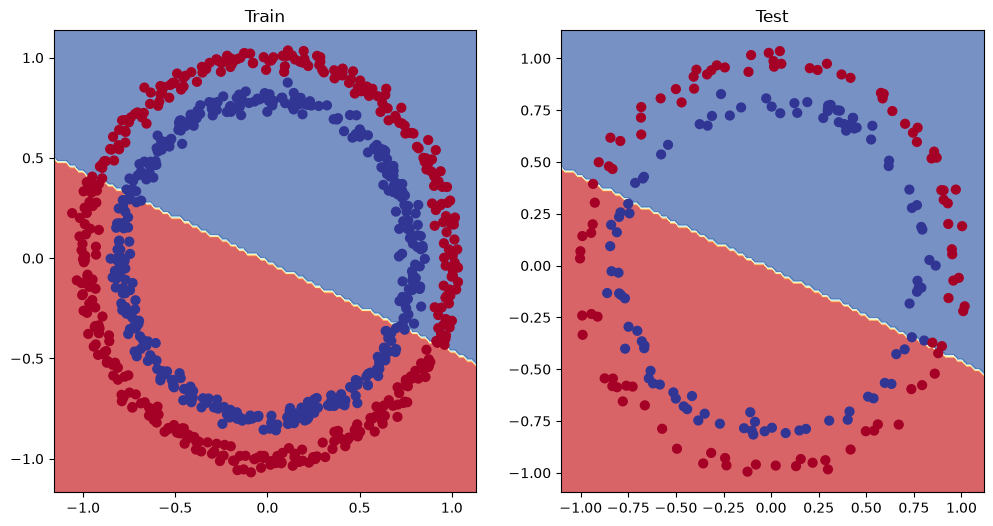

In [965]:
plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.title("Train")
plot_decision_boundary(model_1,X_train,y_train)
plt.subplot(1,2,2)
plt.title("Test")
plot_decision_boundary(model_1,X_test,y_test)


LHFBVKDZFGBZLDGZDDDDDDFHGLIGFLAIDUFGLAKFADLFIU


In [966]:
weight=0.7
bais=0.3

X_regression=torch.arange(0,1,0.01).unsqueeze(dim=1)
y_regression=weight*X_regression+bais

len(X_regression),len(y_regression)

(100, 100)

In [967]:
X_regression[:5],y_regression[:5]

(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280]]))

In [968]:
train_split=int(0.8*len(X_regression))
X_train_regression,y_train_regression=X_regression[:train_split],y_regression[:train_split]
X_test_regression,y_test_regression=X_regression[train_split:],y_regression[train_split:]

len(X_train_regression),len(X_test_regression),len(y_train_regression),len(y_test_regression)

(80, 20, 80, 20)

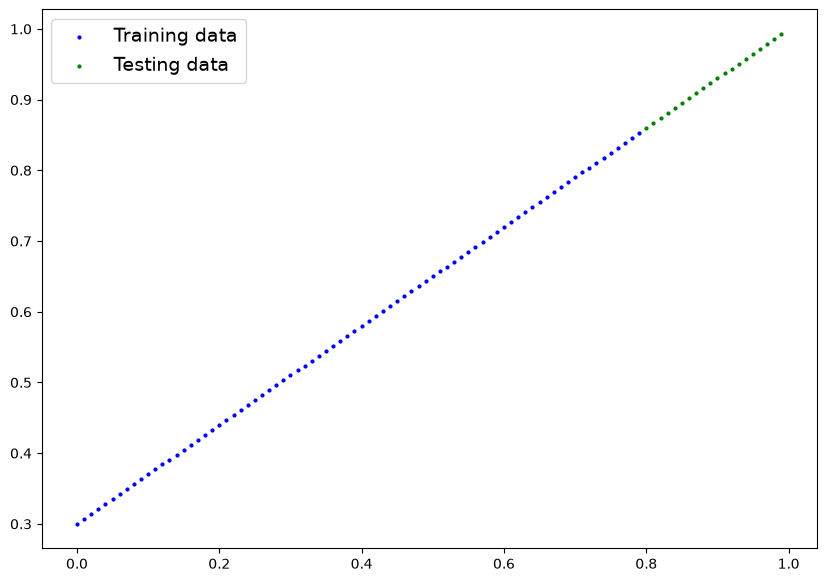

In [969]:
plot_predictions(train_data=X_train_regression,train_labels=y_train_regression,test_data=X_test_regression,test_labels=y_test_regression)

In [970]:
X_train_regression[:10],y_train_regression[:10]

(tensor([[0.0000],
         [0.0100],
         [0.0200],
         [0.0300],
         [0.0400],
         [0.0500],
         [0.0600],
         [0.0700],
         [0.0800],
         [0.0900]]),
 tensor([[0.3000],
         [0.3070],
         [0.3140],
         [0.3210],
         [0.3280],
         [0.3350],
         [0.3420],
         [0.3490],
         [0.3560],
         [0.3630]]))

In [971]:
X_train_regression.shape

torch.Size([80, 1])

In [972]:
model_1

CircleModel(
  (layer_1): Linear(in_features=2, out_features=10, bias=True)
  (layer_2): Linear(in_features=10, out_features=10, bias=True)
  (layer_3): Linear(in_features=10, out_features=1, bias=True)
)

In [973]:
model_2=nn.Sequential(
    nn.Linear(in_features=1,out_features=10),
    nn.Linear(in_features=10,out_features=10),
    nn.Linear(in_features=10,out_features=1)
).to(device)
model_2

Sequential(
  (0): Linear(in_features=1, out_features=10, bias=True)
  (1): Linear(in_features=10, out_features=10, bias=True)
  (2): Linear(in_features=10, out_features=1, bias=True)
)

In [974]:
loss_fn=nn.L1Loss()
optimizer=torch.optim.SGD(params=model_2.parameters(),lr=0.0 1)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (863215140.py, line 2)

In [ ]:
torch.manual_seed(42)
torch.cuda.manual_seed(42)

X_test_regression=X_test_regression.to(device)
X_train_regression=X_train_regression.to(device)
y_test_regression=y_test_regression.to(device)
y_train_regression=y_train_regression.to(device)

epocs=1000

for epoc in range(epocs):

    y_pred=model_2(X_train_regression)

    loss=loss_fn(y_pred,y_train_regression)

    optimizer.zero_grad()

    loss.backward()

    optimizer.step()

    model_2.eval()

    with torch.inference_mode():
        test_pred=model_2(X_test_regression)
        test_loss=loss_fn(test_pred,y_test_regression)

    if epoc%100==0:
        print(f"Epoc: {epoc} | Loss:{loss:.5f} | Test loss: {test_loss:.5f} | ")




Epoc: 0 | Loss:0.75986 | Test loss: 0.91103 | 
Epoc: 100 | Loss:0.02858 | Test loss: 0.00081 | 
Epoc: 200 | Loss:0.02533 | Test loss: 0.00209 | 
Epoc: 300 | Loss:0.02137 | Test loss: 0.00305 | 
Epoc: 400 | Loss:0.01964 | Test loss: 0.00341 | 
Epoc: 500 | Loss:0.01940 | Test loss: 0.00387 | 
Epoc: 600 | Loss:0.01903 | Test loss: 0.00379 | 
Epoc: 700 | Loss:0.01878 | Test loss: 0.00381 | 
Epoc: 800 | Loss:0.01840 | Test loss: 0.00329 | 
Epoc: 900 | Loss:0.01798 | Test loss: 0.00360 | 


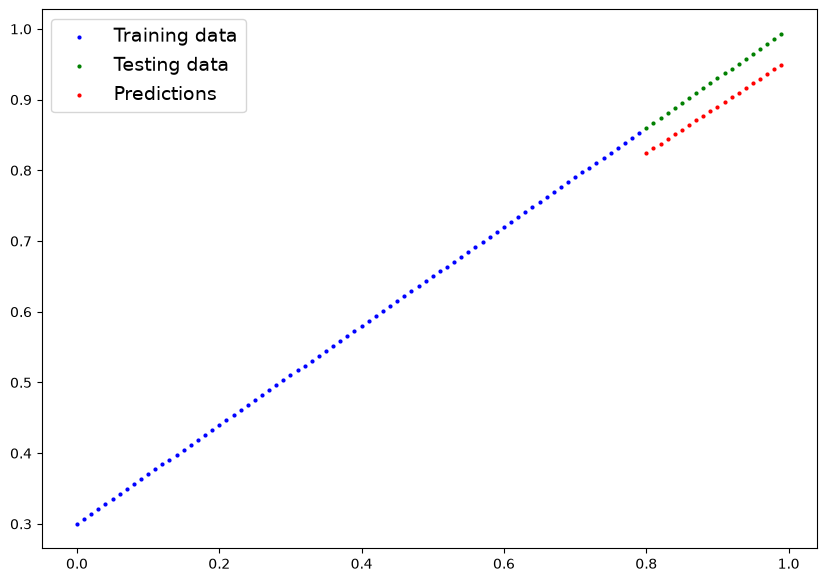

In [ ]:
model_2.eval()
with torch.inference_mode():
    y_preds=model_2(X_test_regression)

plot_predictions(train_data=X_train_regression.cpu(),
                 train_labels=y_train_regression.cpu(),
                 test_data=X_test_regression.cpu(),
                 test_labels=y_test_regression.cpu(),
                 predictions=y_preds.cpu())